<a href="https://colab.research.google.com/github/Divyasharma1910/Image_processing/blob/main/Assignment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


Saving space.jpg to space.jpg


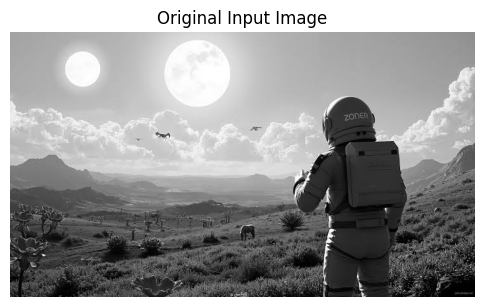

In [ ]:
uploaded = files.upload()

image_path = next(iter(uploaded))

# Read the uploaded image in grayscale
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise ValueError("Unable to read image. Please upload a valid image.")

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Input Image")
plt.axis("off")
plt.show()


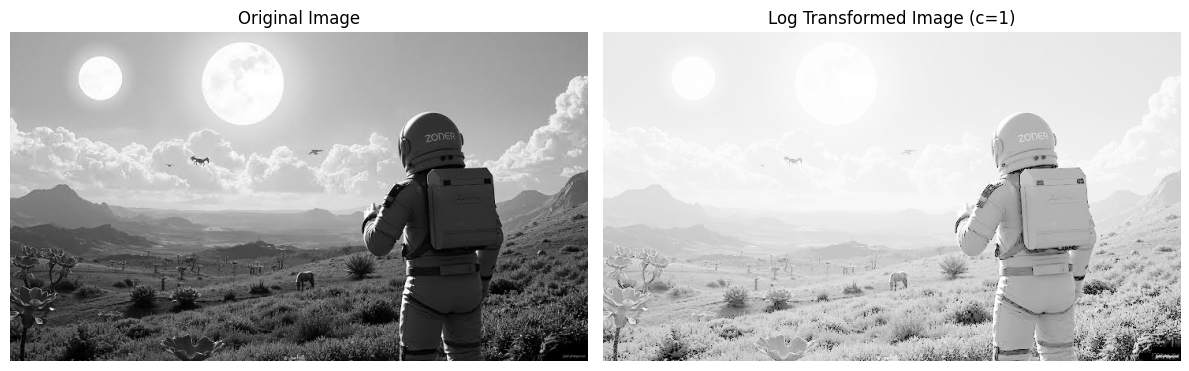

In [ ]:

# Log transformation with c = 1
c = 1

image_float = image.astype(np.float32)

# Apply log transformation
log_image = c * np.log1p(image_float)

# Normalize the result to the range 0-255
log_image = cv2.normalize(
    log_image, None, 0, 255, cv2.NORM_MINMAX
)

log_image = log_image.astype(np.uint8)

# Display original and enhanced images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(log_image, cmap="gray", vmin=0, vmax=255)
plt.title("Log Transformed Image (c=1)")
plt.axis("off")

plt.tight_layout()
plt.show()


Enter the value of gamma: 0.5


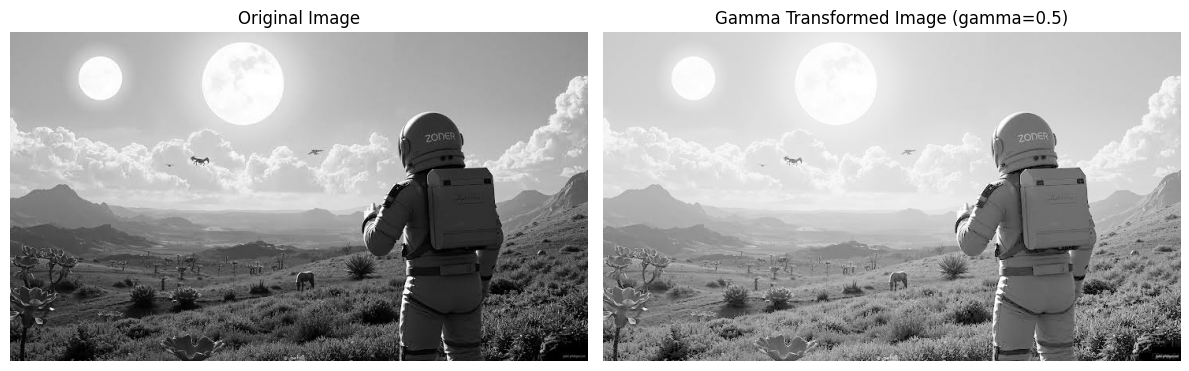

In [ ]:

# Power-law / Gamma transformation
c = 1

gamma = float(input("Enter the value of gamma: "))

if gamma <= 0:
    raise ValueError("Gamma must be greater than zero.")

# Normalize image to 0-1
normalized_image = image.astype(np.float32) / 255.0

# Apply gamma transformation with c = 1
gamma_image = c * np.power(normalized_image, gamma)

# Convert back to 0-255
gamma_image = np.clip(gamma_image * 255, 0, 255)
gamma_image = gamma_image.astype(np.uint8)

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gamma_image, cmap="gray", vmin=0, vmax=255)
plt.title(f"Gamma Transformed Image (gamma={gamma})")
plt.axis("off")

plt.tight_layout()
plt.show()


Enter minimum input intensity (0-255): 80
Enter maximum input intensity (0-255): 120
Enter minimum output intensity (0-255): 50
Enter maximum output intensity (0-255): 150


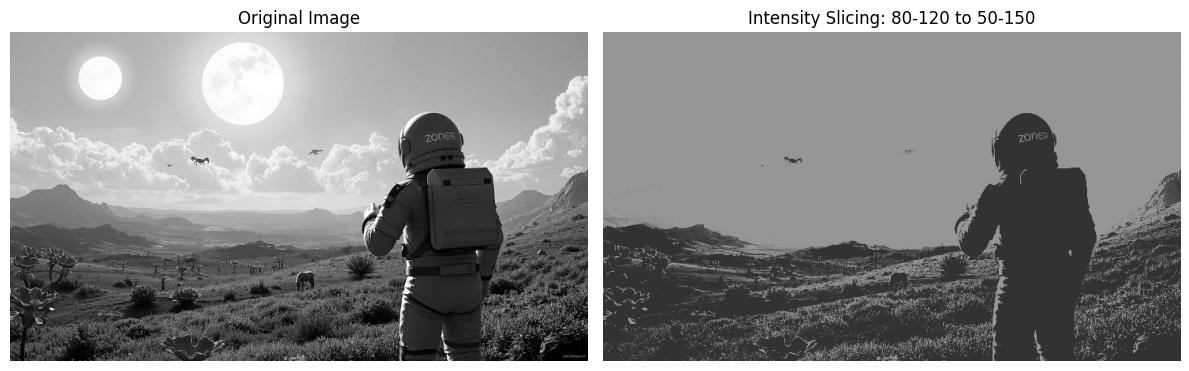

In [ ]:

# Intensity-level slicing / Contrast stretching

r_min = int(input("Enter minimum input intensity (0-255): "))
r_max = int(input("Enter maximum input intensity (0-255): "))

s_min = int(input("Enter minimum output intensity (0-255): "))
s_max = int(input("Enter maximum output intensity (0-255): "))

# Validate input ranges
if not (0 <= r_min < r_max <= 255):
    raise ValueError(
        "Input range must satisfy 0 <= minimum < maximum <= 255."
    )

if not (0 <= s_min <= s_max <= 255):
    raise ValueError(
        "Output values must be between 0 and 255, with minimum <= maximum."
    )

# Convert to float for calculation
image_float = image.astype(np.float32)

# Apply linear mapping and clip to the desired output range
sliced_image = s_min + (
    (image_float - r_min) / (r_max - r_min)
) * (s_max - s_min)

sliced_image = np.clip(sliced_image, s_min, s_max)
sliced_image = np.round(sliced_image).astype(np.uint8)

# Display original and transformed images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sliced_image, cmap="gray", vmin=0, vmax=255)
plt.title(f"Intensity Slicing: {r_min}-{r_max} to {s_min}-{s_max}")
plt.axis("off")

plt.tight_layout()
plt.show()


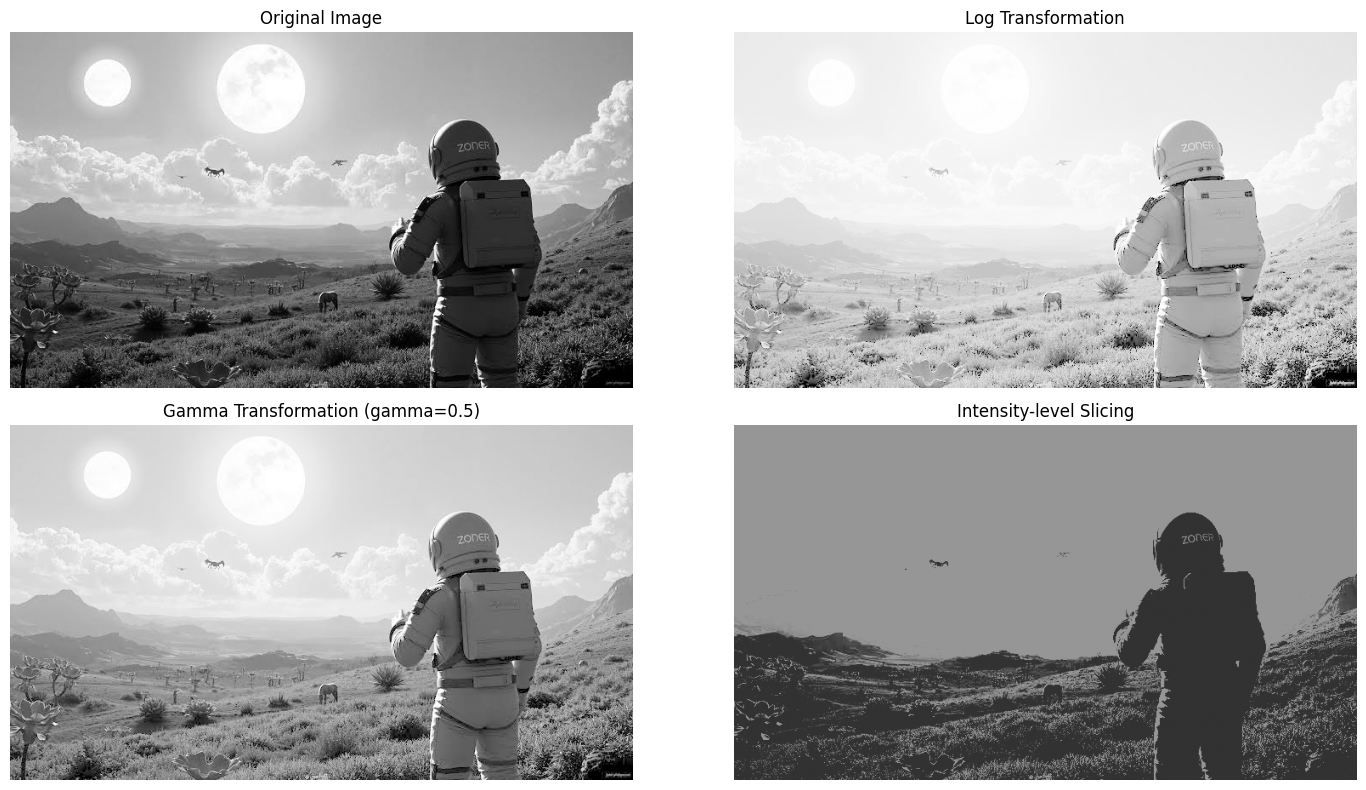

In [ ]:

plt.figure(figsize=(15, 8))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(log_image, cmap="gray", vmin=0, vmax=255)
plt.title("Log Transformation")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(gamma_image, cmap="gray", vmin=0, vmax=255)
plt.title(f"Gamma Transformation (gamma={gamma})")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(sliced_image, cmap="gray", vmin=0, vmax=255)
plt.title("Intensity-level Slicing")
plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import zipfile

output_images = {
    "log_transform.png": log_image,
    "gamma_transform.png": gamma_image,
    "intensity_slicing.png": sliced_image
}

with zipfile.ZipFile("Assignment_4_Results.zip", "w") as z:
    for filename, result in output_images.items():
        cv2.imwrite(filename, result)
        z.write(filename)

print("All three output images saved successfully!")

files.download("Assignment_4_Results.zip")


All three output images saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>